# Perceptrón para Clasificación de Imágenes: Dígitos MNIST

## En este notebook implementaremos un perceptrón para distinguir entre dos clases de dígitos manuscritos del dataset MNIST.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report)
from sklearn.linear_model import Perceptron as SklearnPerceptron
import time
import warnings
warnings.filterwarnings('ignore')

In [7]:
plt.style.use('default')
sns.set_palette("husl")
np.random.seed(42)

print("=== Perceptrón para Clasificación de Imágenes MNIST ===")

=== Perceptrón para Clasificación de Imágenes MNIST ===


### 1. Vamos a cargar y preparar el Dataset MNIST


#### En este primer paso, cargaremos el famoso dataset MNIST que contiene 70,000 imágenes de dígitos manuscritos (28x28 píxeles). Realizaremos una selección binaria específica, escogiendo dos dígitos particulares para transformar el problema multiclase original en uno de clasificación binaria. Este proceso incluye filtrar las imágenes correspondientes a las clases seleccionadas y reetiquetarlas como 0 y 1, estableciendo así las bases para el entrenamiento de nuestro perceptrón.

In [11]:
# Cargar dataset MNIST
print("Cargando dataset MNIST...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X, y = mnist.data, mnist.target.astype(int)

print(f"Dimensiones del dataset: X {X.shape}, y {y.shape}")
print(f"Valores únicos en y: {np.unique(y)}")

Cargando dataset MNIST...
Dimensiones del dataset: X (70000, 784), y (70000,)
Valores únicos en y: [0 1 2 3 4 5 6 7 8 9]


In [13]:
# Seleccionar dos clases para clasificación binaria
clase_0 = 0  # Dígito 0
clase_1 = 1  # Dígito 1

print(f"\nSeleccionando clases {clase_0} vs {clase_1}...")

# Filtrar datos para las dos clases seleccionadas
mask = (y == clase_0) | (y == clase_1)
X_binary = X[mask]
y_binary = y[mask]

# Convertir a problema binario: clase_0 → 0, clase_1 → 1
y_binary = (y_binary == clase_1).astype(int)

print(f"Dataset filtrado: X {X_binary.shape}, y {y_binary.shape}")
print(f"Distribución de clases: Clase 0: {np.sum(y_binary == 0)}, Clase 1: {np.sum(y_binary == 1)}")


Seleccionando clases 0 vs 1...
Dataset filtrado: X (14780, 784), y (14780,)
Distribución de clases: Clase 0: 6903, Clase 1: 7877


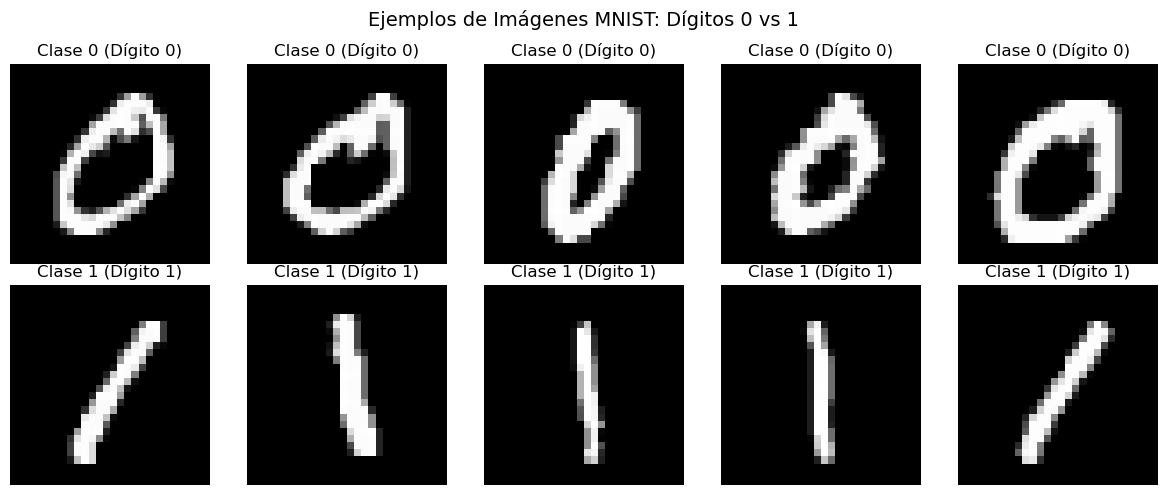

In [15]:
# Visualización de ejemplos de cada clase
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Ejemplos clase 0
class_0_indices = np.where(y_binary == 0)[0][:5]
for i, idx in enumerate(class_0_indices):
    axes[0, i].imshow(X_binary[idx].reshape(28, 28), cmap='gray')
    axes[0, i].set_title(f'Clase 0 (Dígito {clase_0})')
    axes[0, i].axis('off')

# Ejemplos clase 1
class_1_indices = np.where(y_binary == 1)[0][:5]
for i, idx in enumerate(class_1_indices):
    axes[1, i].imshow(X_binary[idx].reshape(28, 28), cmap='gray')
    axes[1, i].set_title(f'Clase 1 (Dígito {clase_1})')
    axes[1, i].axis('off')

plt.suptitle(f'Ejemplos de Imágenes MNIST: Dígitos {clase_0} vs {clase_1}', fontsize=14)
plt.tight_layout()
plt.show()

### 2. Implementación del Perceptrón para Clasificación

#### Desarrollaremos una implementación personalizada del algoritmo del perceptrón desde cero, diseñada específicamente para problemas de clasificación binaria. Esta implementación incluirá:

#### * la función de activación escalón.

#### * la regla de aprendizaje del perceptrón para actualización de pesos.

#### * mecanismos para almacenar el historial de entrenamiento. 

#### La clase encapsulará toda la lógica necesaria para el entrenamiento iterativo y la posterior evaluación del modelo.


In [18]:
class PerceptronClasificacion:
    """
    Implementación de perceptrón para clasificación binaria
    """
    
    def __init__(self, learning_rate=0.01, n_epochs=100, random_state=42):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.random_state = random_state
        self.w = None  # pesos
        self.b = None  # bias
        self.loss_history = []
        self.accuracy_history = []
        
    def initialize_parameters(self, n_features):
        """Inicializa pesos y bias"""
        np.random.seed(self.random_state)
        self.w = np.random.normal(0, 0.01, n_features)
        self.b = np.random.normal(0, 0.01)
        
    def activation_function(self, z):
        """Función de activación escalón (para clasificación)"""
        return (z >= 0).astype(int)
    
    def predict_proba(self, X):
        """Calcula probabilidades (score lineal)"""
        return np.dot(X, self.w) + self.b
    
    def predict(self, X):
        """Predice clases (0 o 1)"""
        scores = self.predict_proba(X)
        return self.activation_function(scores)
    
    def compute_accuracy(self, X, y):
        """Calcula accuracy"""
        y_pred = self.predict(X)
        return np.mean(y_pred == y)
    
    def fit(self, X, y, verbose=True):
        """
        Entrena el perceptrón usando la regla de aprendizaje del perceptrón
        """
        n_samples, n_features = X.shape
        
        # Inicializar parámetros
        self.initialize_parameters(n_features)
        
        # Historial
        self.loss_history = []
        self.accuracy_history = []
        
        print("Iniciando entrenamiento del perceptrón...")
        start_time = time.time()
        
        for epoch in range(self.n_epochs):
            errors = 0
            
            for i in range(n_samples):
                # Predicción
                prediction = self.predict(X[i].reshape(1, -1))[0]
                
                # Calcular error
                error = y[i] - prediction
                
                # Si hay error, actualizar pesos
                if error != 0:
                    self.w += self.learning_rate * error * X[i]
                    self.b += self.learning_rate * error
                    errors += 1
            
            # Calcular métricas
            accuracy = self.compute_accuracy(X, y)
            self.accuracy_history.append(accuracy)
            self.loss_history.append(errors / n_samples)
            
            # Mostrar progreso
            if verbose and (epoch % 20 == 0 or epoch == self.n_epochs - 1):
                print(f"Época {epoch:3d}: Accuracy = {accuracy:.4f}, Errores = {errors}")
        
        training_time = time.time() - start_time
        print(f"\nEntrenamiento completado en {training_time:.2f} segundos")
        print(f"Accuracy final en entrenamiento: {self.accuracy_history[-1]:.4f}")
        
    def get_parameters(self):
        """Retorna parámetros del modelo"""
        return {'weights': self.w, 'bias': self.b}

### 3. Preprocesamiento de Datos

#### Prepararemos los datos para el entrenamiento mediante técnicas esenciales de preprocesamiento. Dividiremos el dataset en conjuntos de entrenamiento y prueba manteniendo la proporción de clases, y aplicaremos escalado estándar a las características para normalizar los valores de píxeles. Este último paso es crucial para garantizar la estabilidad numérica durante el entrenamiento y acelerar la convergencia del algoritmo.

In [21]:
# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_binary, y_binary, test_size=0.3, random_state=42, stratify=y_binary
)

print(f"Tamaño entrenamiento: {X_train.shape[0]}")
print(f"Tamaño prueba: {X_test.shape[0]}")
print(f"Proporción clases en entrenamiento: Clase 0: {np.mean(y_train == 0):.3f}, Clase 1: {np.mean(y_train == 1):.3f}")

# Escalar características (importante para perceptrón)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype(float))
X_test_scaled = scaler.transform(X_test.astype(float))

print("\nEstadísticas después del escalado:")
print(f"Media X_train: {np.mean(X_train_scaled):.4f}")
print(f"Desviación X_train: {np.std(X_train_scaled):.4f}")

Tamaño entrenamiento: 10346
Tamaño prueba: 4434
Proporción clases en entrenamiento: Clase 0: 0.467, Clase 1: 0.533

Estadísticas después del escalado:
Media X_train: 0.0000
Desviación X_train: 0.8792


### 4. Entrenamiento del Perceptrón

#### Ejecutaremos el proceso de entrenamiento del perceptrón mediante el algoritmo de aprendizaje iterativo. En cada época, el modelo procesará todas las muestras de entrenamiento, ajustando los pesos y el bias cada vez que cometa un error de clasificación. Monitorizaremos el progreso mediante el cálculo periódico del accuracy, observando cómo el modelo mejora gradualmente su capacidad de distinguir entre las dos clases seleccionadas.

Iniciando entrenamiento del perceptrón...
Época   0: Accuracy = 0.9977, Errores = 59
Época  20: Accuracy = 1.0000, Errores = 0
Época  40: Accuracy = 1.0000, Errores = 0
Época  60: Accuracy = 1.0000, Errores = 0
Época  80: Accuracy = 1.0000, Errores = 0
Época  99: Accuracy = 1.0000, Errores = 0

Entrenamiento completado en 6.26 segundos
Accuracy final en entrenamiento: 1.0000


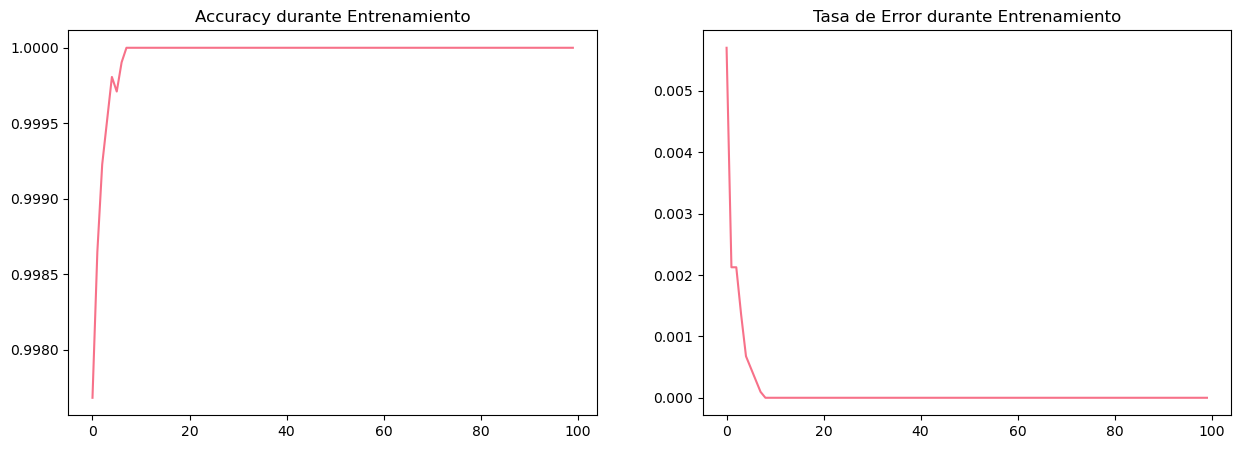

In [65]:
# Visualización del entrenamiento
perceptron_corregido = PerceptronClasificacion(learning_rate=0.01, n_epochs=100)
perceptron_corregido.fit(X_train_scaled, y_train)

# Reemplazar el modelo original
perceptron = perceptron_corregido

# Ahora los gráficos deberían funcionar
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(perceptron.accuracy_history)
axes[0].set_title('Accuracy durante Entrenamiento')
axes[1].plot(perceptron.loss_history) 
axes[1].set_title('Tasa de Error durante Entrenamiento')
plt.show()

### 5. Evaluación del Modelo

#### Realizaremos una evaluación exhaustiva del modelo entrenado utilizando el conjunto de prueba. Calcularemos métricas fundamentales como accuracy, precision, recall y F1-score para cuantificar el rendimiento del perceptrón. Además, generaremos una matriz de confusión que nos permitirá visualizar los tipos de aciertos y errores cometidos por el clasificador.

EVALUACIÓN EN CONJUNTO DE PRUEBA:
Accuracy:  0.9984
Precision: 0.9992
Recall:    0.9979
F1-Score:  0.9985


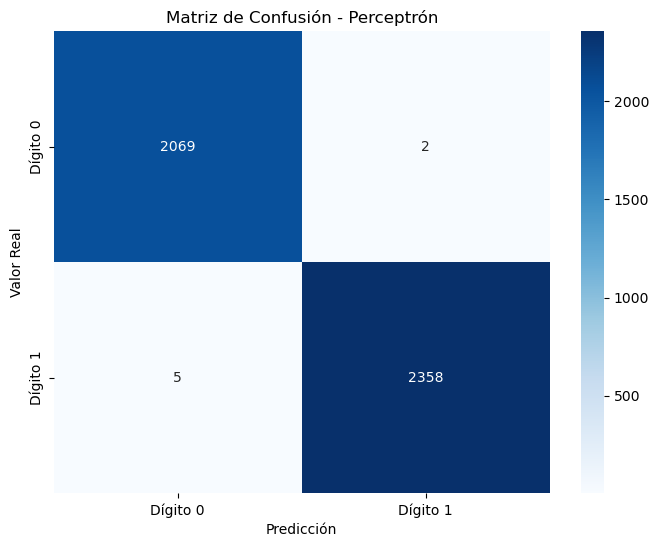

In [31]:
# Predicciones en conjunto de prueba
y_pred = perceptron.predict(X_test_scaled)

# Métricas de evaluación
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("EVALUACIÓN EN CONJUNTO DE PRUEBA:")
print("=" * 50)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# %% [python]
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[f'Dígito {clase_0}', f'Dígito {clase_1}'], 
            yticklabels=[f'Dígito {clase_0}', f'Dígito {clase_1}'])
plt.title('Matriz de Confusión - Perceptrón')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

In [33]:
# Reporte de clasificación detallado
print("\nREPORTE DE CLASIFICACIÓN:")
print("=" * 40)
print(classification_report(y_test, y_pred, 
                           target_names=[f'Dígito {clase_0}', f'Dígito {clase_1}']))


REPORTE DE CLASIFICACIÓN:
              precision    recall  f1-score   support

    Dígito 0       1.00      1.00      1.00      2071
    Dígito 1       1.00      1.00      1.00      2363

    accuracy                           1.00      4434
   macro avg       1.00      1.00      1.00      4434
weighted avg       1.00      1.00      1.00      4434



### 6. Visualización de Predicciones

#### Visualizaremos ejemplos concretos de predicciones del modelo, mostrando imágenes reales junto con sus etiquetas verdaderas y las predicciones generadas. Esta representación gráfica nos permitirá identificar patrones en los aciertos y errores, además de proporcionar una comprensión intuitiva del desempeño del clasificador en casos específicos.

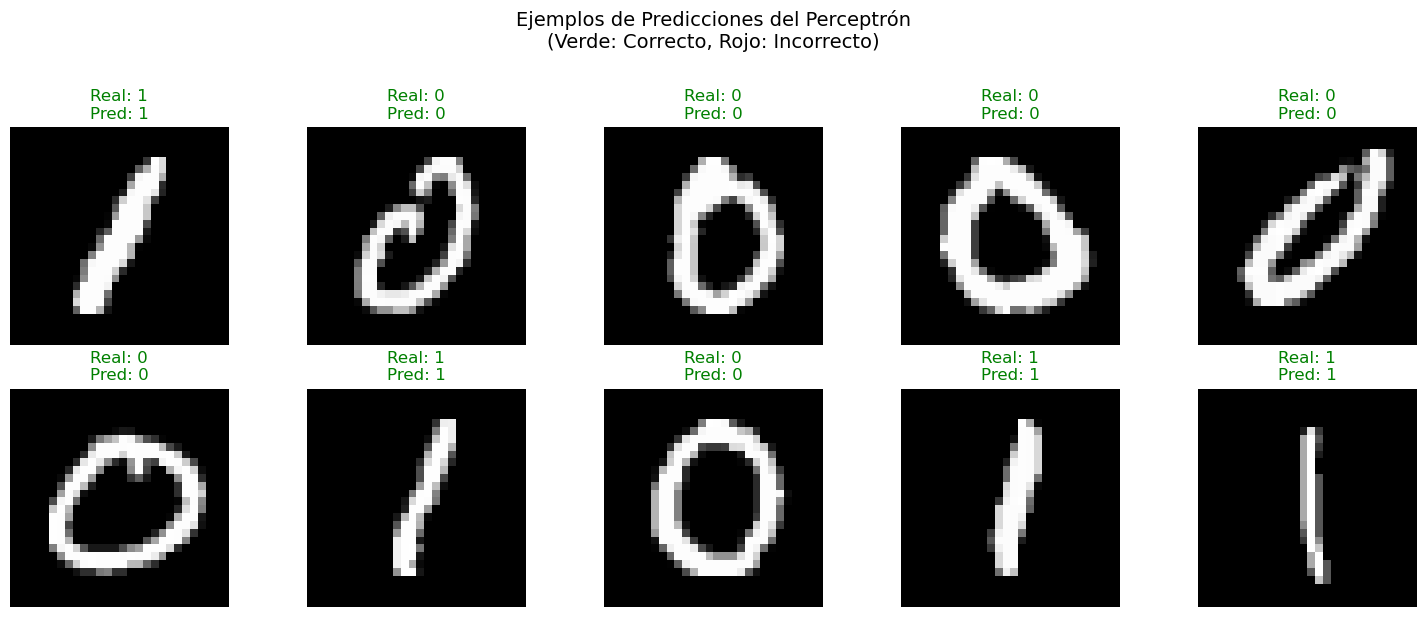

In [36]:
# Seleccionar algunas muestras para visualización
n_samples_to_show = 10
indices = np.random.choice(len(X_test), n_samples_to_show, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, idx in enumerate(indices):
    # Obtener muestra
    image = X_test[idx].reshape(28, 28)
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    
    # Visualizar
    axes[i].imshow(image, cmap='gray')
    color = 'green' if true_label == pred_label else 'red'
    axes[i].set_title(f'Real: {clase_0 if true_label == 0 else clase_1}\n'
                      f'Pred: {clase_0 if pred_label == 0 else clase_1}', 
                      color=color)
    axes[i].axis('off')

plt.suptitle('Ejemplos de Predicciones del Perceptrón\n(Verde: Correcto, Rojo: Incorrecto)', 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 7. Análisis de los Pesos Aprendidos

#### En este punto vamos a investigar los parámetros internos del modelo mediante la visualización e interpretación de los pesos aprendidos. Representaremos el vector de pesos como una imagen 28x28 píxeles que actuará como un "filtro" aprendido, revelando qué características de las imágenes el perceptrón considera más relevantes para la clasificación. También analizaremos la distribución estadística de estos pesos.

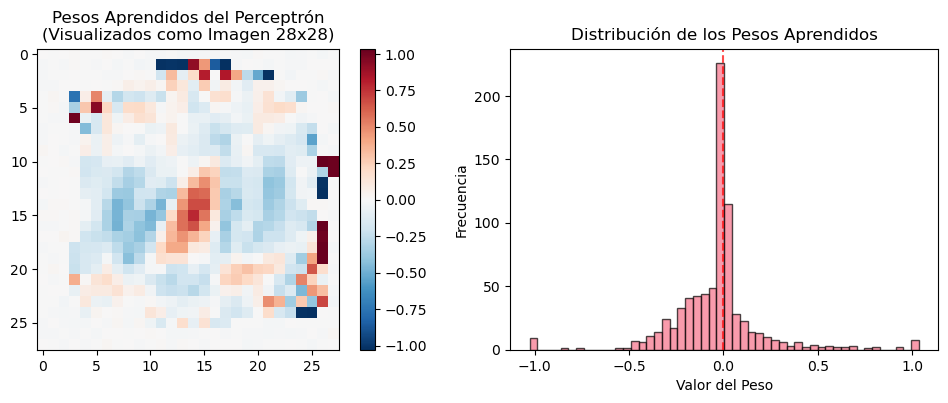

Estadísticas de los pesos:
  Media: -0.031487
  Desviación estándar: 0.242637
  Mínimo: -1.027059
  Máximo: 1.036306
  Bias: -0.264402


In [39]:
# Visualizar los pesos como imagen (filtro aprendido)
weights_image = perceptron.w.reshape(28, 28)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(weights_image, cmap='RdBu_r', interpolation='nearest')
plt.colorbar()
plt.title('Pesos Aprendidos del Perceptrón\n(Visualizados como Imagen 28x28)')

plt.subplot(1, 2, 2)
# Mostrar histograma de pesos
plt.hist(perceptron.w, bins=50, alpha=0.7, edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', alpha=0.7)
plt.title('Distribución de los Pesos Aprendidos')
plt.xlabel('Valor del Peso')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

print(f"Estadísticas de los pesos:")
print(f"  Media: {np.mean(perceptron.w):.6f}")
print(f"  Desviación estándar: {np.std(perceptron.w):.6f}")
print(f"  Mínimo: {np.min(perceptron.w):.6f}")
print(f"  Máximo: {np.max(perceptron.w):.6f}")
print(f"  Bias: {perceptron.b:.6f}")

### 8. Comparación con Perceptrón de scikit-learn

#### Ahora estableceremos un punto de referencia comparativo entrenando el perceptrón implementado en scikit-learn con los mismos datos y parámetros. Esta comparación nos permitirá validar la corrección de nuestra implementación personalizada y identificar posibles diferencias en el comportamiento de ambos modelos, particularmente en los valores finales de los parámetros aprendidos.

In [42]:
# Entrenar perceptrón de scikit-learn para comparación
sklearn_perceptron = SklearnPerceptron(
    alpha=0.0,  # Sin regularización para comparación justa
    max_iter=100,
    random_state=42,
    tol=None
)

sklearn_perceptron.fit(X_train_scaled, y_train)
y_pred_sklearn = sklearn_perceptron.predict(X_test_scaled)

accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)

print("COMPARACIÓN CON SCIKIT-LEARN:")
print("=" * 40)
print(f"Nuestro perceptrón:     {accuracy:.4f}")
print(f"Scikit-learn perceptrón: {accuracy_sklearn:.4f}")
print(f"Diferencia: {abs(accuracy - accuracy_sklearn):.4f}")

# Comparar parámetros
print(f"\nComparación de parámetros:")
print(f"Nuestro bias: {perceptron.b:.6f}")
print(f"Sklearn bias: {sklearn_perceptron.intercept_[0]:.6f}")
print(f"Diferencia en bias: {abs(perceptron.b - sklearn_perceptron.intercept_[0]):.6f}")

COMPARACIÓN CON SCIKIT-LEARN:
Nuestro perceptrón:     0.9984
Scikit-learn perceptrón: 0.9971
Diferencia: 0.0014

Comparación de parámetros:
Nuestro bias: -0.264402
Sklearn bias: -14.000000
Diferencia en bias: 13.735598


### 9. Prueba con Diferentes Pares de Dígitos

#### Ampliaremos el análisis probando el perceptrón en múltiples combinaciones de pares de dígitos con distintos grados de similitud visual. Este experimento sistemático nos permitirá evaluar cómo la complejidad de la tarea de clasificación afecta el rendimiento del modelo y identificar qué pares de dígitos presentan mayores desafíos para un clasificador lineal.

In [45]:
def entrenar_perceptron_digitos(digit1, digit2, n_epochs=50):
    """
    Función para entrenar perceptrón en diferentes pares de dígitos
    """
    print(f"\n{'='*50}")
    print(f"ENTRENANDO PERCEPTRÓN: {digit1} vs {digit2}")
    print(f"{'='*50}")
    
    # Filtrar datos
    mask = (y == digit1) | (y == digit2)
    X_bin = X[mask]
    y_bin = (y[mask] == digit2).astype(int)  # digit1 → 0, digit2 → 1
    
    # Dividir datos
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_bin, y_bin, test_size=0.3, random_state=42, stratify=y_bin
    )
    
    # Escalar
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr.astype(float))
    X_te_scaled = scaler.transform(X_te.astype(float))
    
    # Entrenar perceptrón
    perc = PerceptronClasificacion(
        learning_rate=0.01, 
        n_epochs=n_epochs,
        random_state=42
    )
    perc.fit(X_tr_scaled, y_tr, verbose=False)
    
    # Evaluar
    y_pred = perc.predict(X_te_scaled)
    accuracy = accuracy_score(y_te, y_pred)
    
    print(f"Accuracy {digit1} vs {digit2}: {accuracy:.4f}")
    print(f"Tamaño dataset: {X_bin.shape[0]} muestras")
    
    return accuracy, X_bin.shape[0]

# Probar diferentes pares de dígitos
pares_digitos = [(0, 1), (3, 8), (4, 7), (2, 5), (6, 9)]
resultados = []

for digit1, digit2 in pares_digitos:
    accuracy, n_muestras = entrenar_perceptron_digitos(digit1, digit2)
    resultados.append({
        'par': f"{digit1} vs {digit2}",
        'accuracy': accuracy,
        'n_muestras': n_muestras
    })



ENTRENANDO PERCEPTRÓN: 0 vs 1
Iniciando entrenamiento del perceptrón...

Entrenamiento completado en 2.77 segundos
Accuracy final en entrenamiento: 1.0000
Accuracy 0 vs 1: 0.9984
Tamaño dataset: 14780 muestras

ENTRENANDO PERCEPTRÓN: 3 vs 8
Iniciando entrenamiento del perceptrón...

Entrenamiento completado en 3.21 segundos
Accuracy final en entrenamiento: 0.9618
Accuracy 3 vs 8: 0.9413
Tamaño dataset: 13966 muestras

ENTRENANDO PERCEPTRÓN: 4 vs 7
Iniciando entrenamiento del perceptrón...

Entrenamiento completado en 2.53 segundos
Accuracy final en entrenamiento: 0.9984
Accuracy 4 vs 7: 0.9823
Tamaño dataset: 14117 muestras

ENTRENANDO PERCEPTRÓN: 2 vs 5
Iniciando entrenamiento del perceptrón...

Entrenamiento completado en 2.56 segundos
Accuracy final en entrenamiento: 0.9928
Accuracy 2 vs 5: 0.9642
Tamaño dataset: 13303 muestras

ENTRENANDO PERCEPTRÓN: 6 vs 9
Iniciando entrenamiento del perceptrón...

Entrenamiento completado en 2.86 segundos
Accuracy final en entrenamiento: 1.0000


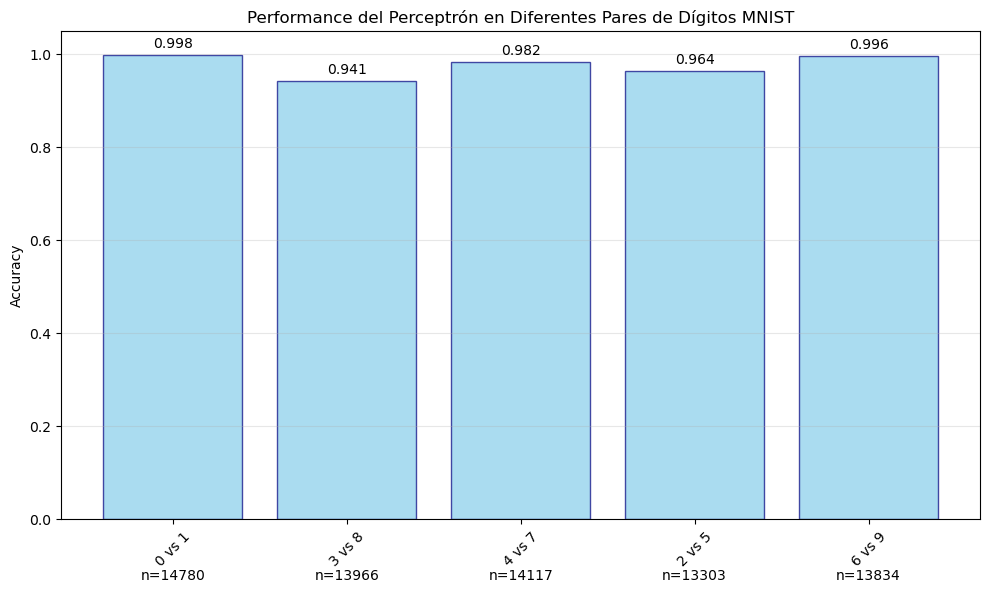

In [47]:
# Visualizar resultados comparativos
fig, ax = plt.subplots(figsize=(10, 6))

pares = [r['par'] for r in resultados]
accuracies = [r['accuracy'] for r in resultados]
n_muestras = [r['n_muestras'] for r in resultados]

bars = ax.bar(pares, accuracies, color='skyblue', edgecolor='navy', alpha=0.7)

# Añadir valores en las barras
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
            f'{acc:.3f}', ha='center', va='bottom')

ax.set_ylabel('Accuracy')
ax.set_title('Performance del Perceptrón en Diferentes Pares de Dígitos MNIST')
ax.set_ylim(0, 1.05)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3, axis='y')

# Añadir información de tamaño de dataset
for i, (pa, n) in enumerate(zip(pares, n_muestras)):
    ax.text(i, -0.1, f'n={n}', ha='center', va='top', transform=ax.get_xaxis_transform())

plt.tight_layout()
plt.show()

### 10. Análisis de Casos Difíciles

#### Finalmente vamos a examinar en detalle los casos donde el modelo comete errores de clasificación, buscando patrones comunes en las imágenes mal clasificadas. Con este ejercicio podremos estimar en un caso muy simple, tanto las capacidades como las limitaciones fundamentales del perceptrón para problemas de clasificación de imágenes.


Análisis de 7 errores de clasificación:


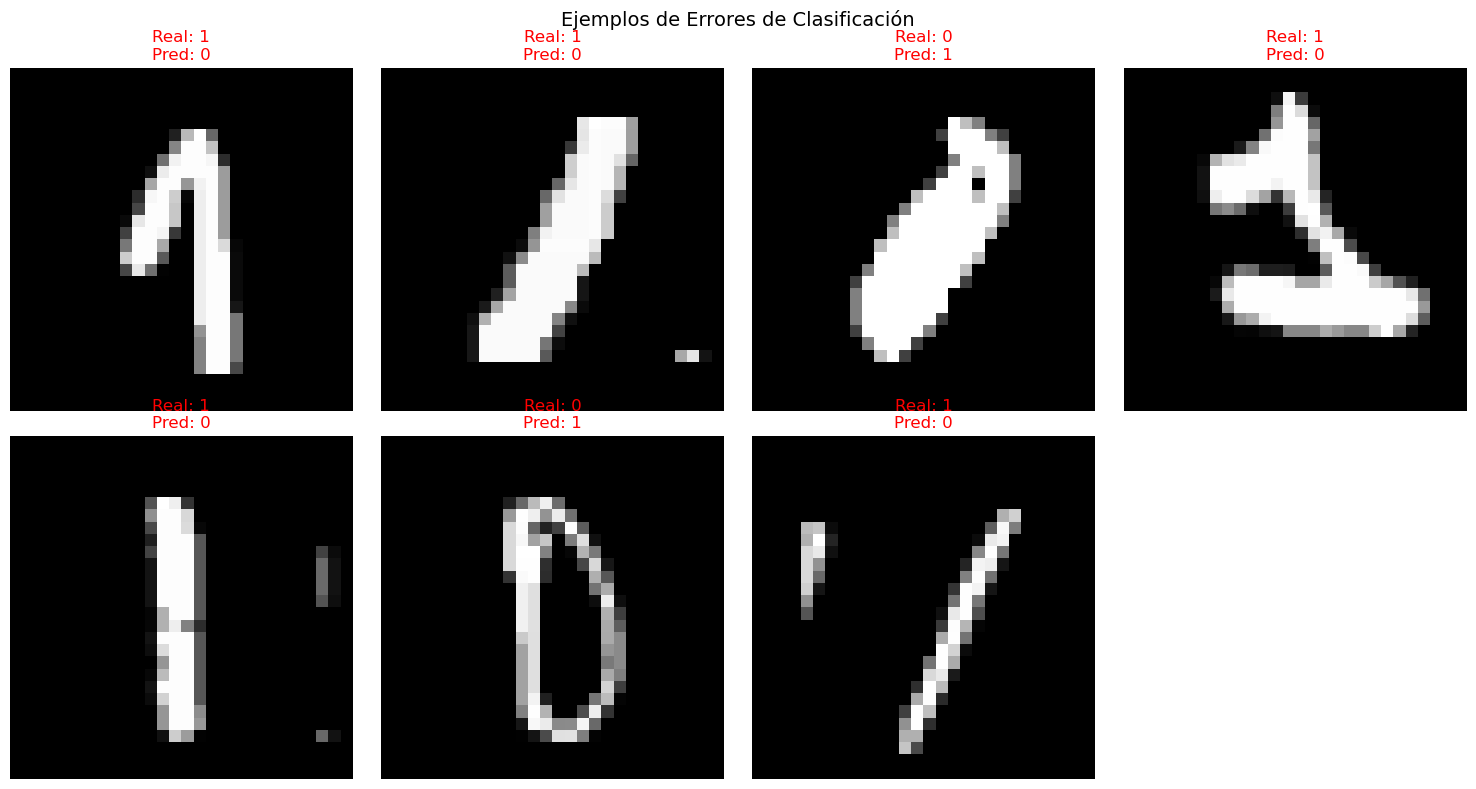

In [50]:
# Encontrar casos donde el modelo se equivoca
misclassified_indices = np.where(y_pred != y_test)[0]

if len(misclassified_indices) > 0:
    print(f"\nAnálisis de {len(misclassified_indices)} errores de clasificación:")
    
    # Tomar algunos ejemplos de errores
    n_error_samples = min(8, len(misclassified_indices))
    error_indices = misclassified_indices[:n_error_samples]
    
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    axes = axes.flatten()
    
    for i, idx in enumerate(error_indices):
        image = X_test[idx].reshape(28, 28)
        true_label = y_test[idx]
        pred_label = y_pred[idx]
        
        axes[i].imshow(image, cmap='gray')
        axes[i].set_title(f'Real: {clase_0 if true_label == 0 else clase_1}\n'
                         f'Pred: {clase_0 if pred_label == 0 else clase_1}', 
                         color='red')
        axes[i].axis('off')
    
    # Ocultar ejes sobrantes
    for i in range(len(error_indices), len(axes)):
        axes[i].set_visible(False)
    
    plt.suptitle('Ejemplos de Errores de Clasificación', fontsize=14, y=0.98)
    plt.tight_layout()
    plt.show()

In [58]:
# Análisis de tipos de error
false_positives = np.sum((y_pred == 1) & (y_test == 0))
false_negatives = np.sum((y_pred == 0) & (y_test == 1))
    
print(f"False Positives (clase 1 predicha como 0): {false_positives}")
print(f"False Negatives (clase 0 predicha como 1): {false_negatives}")

False Positives (clase 1 predicha como 0): 2
False Negatives (clase 0 predicha como 1): 5


### 11. Resumen detras del modelo.

#### Arquitectura: 784 → 1

#### Capa de Entrada: 784 neuronas (28×28 píxeles = 784 características)

#### Capa de Salida: 1 neurona (clasificación binaria)

#### Conexiones: 784 pesos + 1 bias = 785 parámetros entrenables

#### Función de Activación: Escalón unitario (Heaviside)

#### Forward Pass:

$$
z = \sum_{i=1}^{784} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b
$$


$$
\hat{y} = 
\begin{cases} 
1 & \text{si } z \geq 0 \\
0 & \text{si } z < 0 
\end{cases}
$$

#### Backward Pass (Regla de Aprendizaje):

$$
\Delta w_i = \eta \cdot (y - \hat{y}) \cdot x_i
$$

$$
\Delta b = \eta \cdot (y - \hat{y})
$$

#### El perceptrón implementa un hiperplano de decisión en un espacio 784-dimensional:

$$
w_1x_1 + w_2x_2 + \cdots + w_{784}x_{784} + b = 0
$$